# DS-A3: Regression Baseline and Diagnostics
## 1. Introduction and Dataset
Predict one-year disease progression using all ten original features in the [sklearn Diabetes dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset). Load raw inputs with `scaled=False`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import statsmodels.api as sm
from IPython.display import display
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
pd.options.display.float_format = '{:.3f}'.format
plt.rcParams.update({'figure.figsize': (7, 3.6), 'figure.dpi': 120, 'font.size': 10})
data = load_diabetes(scaled=False, as_frame=True)
X, y = data.data, data.target
print('Shape:', X.shape, '| sklearn:', sklearn.__version__)
print('Missing target:', y.isna().sum(), '| duplicate rows:', X.duplicated().sum())
display(pd.DataFrame({'missing': X.isna().sum(), 'min': X.min(), 'max': X.max()}))

Shape: (442, 10) | sklearn: 1.7.2
Missing target: 0 | duplicate rows: 0


,missing,min,max
age,0,19.000,79.000
sex,0,1.000,2.000
bmi,0,18.000,42.200
bp,0,62.000,133.000
s1,0,97.000,301.000
s2,0,41.600,242.400
s3,0,22.000,99.000
s4,0,2.000,9.090
s5,0,3.258,6.107
s6,0,58.000,124.000


## 2. Data Splitting and Leakage Audit
Use an 80/20 split and five-fold training CV. Scaling stays inside each pipeline, so validation and test rows do not affect it. Select models using training CV MAE before test evaluation.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
cv = list(KFold(n_splits=5, shuffle=True, random_state=SEED).split(X_train))
assert set(X_train.index).isdisjoint(X_test.index)
print('Train:', len(X_train), '| Test:', len(X_test))

Train: 353 | Test: 89


## 3. Baseline and Model Training
Compare the mean baseline, Linear, Ridge, and Lasso. Ridge and Lasso use `alpha = [0.1, 1, 10, 100]`; the table keeps every configuration and fold score.

In [3]:
alphas = [0.1, 1, 10, 100]
models = {
    'Dummy': DummyRegressor(strategy='mean'),
    'Linear': Pipeline([('scale', StandardScaler()), ('reg', LinearRegression())]),
    'Ridge': Pipeline([('scale', StandardScaler()), ('reg', Ridge())]),
    'Lasso': Pipeline([('scale', StandardScaler()), ('reg', Lasso(max_iter=10000))])
}
fitted, cv_rows, tuning_rows = {}, [], []
for name, model in models.items():
    grid = {'reg__alpha': alphas} if name in ('Ridge', 'Lasso') else {}
    search = GridSearchCV(model, grid, cv=cv, scoring='neg_mean_absolute_error')
    search.fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    cv_rows.append({'Model': name, 'alpha': search.best_params_.get('reg__alpha', np.nan),
                    'CV_MAE': -search.best_score_,
                    'CV_SD': search.cv_results_['std_test_score'][search.best_index_]})
    if grid:
        for i, alpha in enumerate(alphas):
            row = {'Model': name, 'alpha': alpha,
                   'CV_MAE': -search.cv_results_['mean_test_score'][i]}
            row.update({f'fold_{k+1}': -search.cv_results_[f'split{k}_test_score'][i]
                        for k in range(5)})
            tuning_rows.append(row)
cv_table = pd.DataFrame(cv_rows).set_index('Model')
display(pd.DataFrame(tuning_rows))

,Model,alpha,CV_MAE,fold_1,fold_2,fold_3,fold_4,fold_5
0,Ridge,0.100,45.041,44.575,48.268,42.893,44.317,45.153
1,Ridge,1.000,44.999,44.473,48.208,42.678,44.422,45.214
2,Ridge,10.000,45.060,44.544,48.336,42.256,44.787,45.379
3,Ridge,100.000,46.047,44.615,50.904,42.174,46.722,45.822
4,Lasso,0.100,44.956,44.434,48.209,42.564,44.443,45.128
5,Lasso,1.000,45.136,44.404,48.355,42.194,45.070,45.656
6,Lasso,10.000,48.298,46.161,53.531,43.161,48.737,49.901
7,Lasso,100.000,66.867,62.863,74.052,58.431,67.769,71.222


In [4]:
selected_name = cv_table['CV_MAE'].idxmin()
final_model = fitted[selected_name]
print('Selected by CV:', selected_name, '| alpha:', cv_table.loc[selected_name, 'alpha'])

Selected by CV: Lasso | alpha: 0.1


## 4. Model Comparison
Lasso has the lowest CV MAE (44.956). Its improvement over Linear is only 0.093, so regularization adds little here.

In [5]:
comparison = cv_table.copy()
results = pd.DataFrame({'sample_id': X_test.index, 'actual': y_test.to_numpy(),
                        'bmi': X_test['bmi'].to_numpy()})
for name, model in fitted.items():
    pred = model.predict(X_test)
    comparison.loc[name, 'Test_MAE'] = mean_absolute_error(y_test, pred)
    comparison.loc[name, 'Test_RMSE'] = np.sqrt(mean_squared_error(y_test, pred))
    comparison.loc[name, 'Test_R2'] = r2_score(y_test, pred)
    results[f'{name}_predicted'] = pred
    results[f'{name}_residual'] = y_test.to_numpy() - pred
    results[f'{name}_absolute_error'] = np.abs(y_test.to_numpy() - pred)
results['selected_model'] = selected_name
results['predicted'] = results[f'{selected_name}_predicted']
results['residual'] = results['actual'] - results['predicted']
results['absolute_error'] = results['residual'].abs()
predicted, residual = results['predicted'], results['residual']
display(comparison)

,alpha,CV_MAE,CV_SD,Test_MAE,Test_RMSE,Test_R2
Model,,,,,,
Dummy,NaN,66.867,5.632,64.006,73.222,-0.012
Linear,NaN,45.048,1.773,42.794,53.853,0.453
Ridge,1.000,44.999,1.808,42.812,53.777,0.454
Lasso,0.100,44.956,1.837,42.805,53.709,0.456


## 5. Diagnostics and Error Analysis
### Figure 1: Residuals vs Predicted Values
Residual = actual - predicted. The orange line shows mean residuals in prediction quartiles.

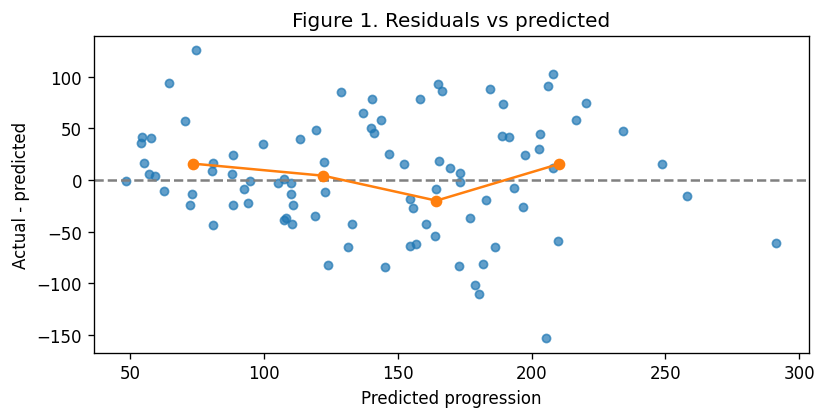

,mean_prediction,mean_residual,MAE
predicted,,,
"(48.623000000000005, 99.8]",73.669,15.766,28.713
"(99.8, 143.666]",122.128,4.145,40.309
"(143.666, 181.937]",164.426,-20.017,50.460
"(181.937, 291.372]",210.156,15.389,52.379


In [6]:
bin_summary = results.groupby(pd.qcut(predicted, 4), observed=True).agg(
    mean_prediction=('predicted', 'mean'), mean_residual=('residual', 'mean'),
    MAE=('absolute_error', 'mean'))
fig, ax = plt.subplots()
ax.scatter(predicted, residual, s=24, alpha=0.7)
ax.axhline(0, color='gray', linestyle='--')
ax.plot(bin_summary['mean_prediction'], bin_summary['mean_residual'], 'o-', color='tab:orange')
ax.set(title='Figure 1. Residuals vs predicted', xlabel='Predicted progression',
       ylabel='Actual - predicted')
fig.tight_layout()
plt.show()
display(bin_summary)

The third prediction quartile has mean residual -20.02, showing local overprediction. There is also considerable scatter around zero.

### Figure 2: Absolute Residuals vs Predicted Values

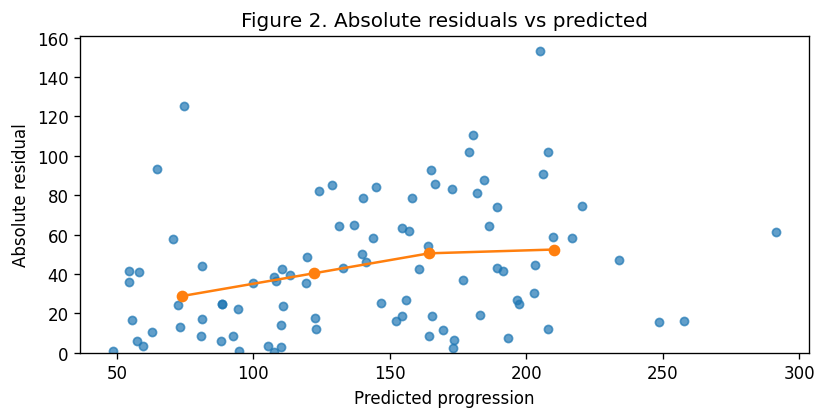

In [7]:
fig, ax = plt.subplots()
ax.scatter(predicted, residual.abs(), s=24, alpha=0.7)
ax.plot(bin_summary['mean_prediction'], bin_summary['MAE'], 'o-', color='tab:orange')
ax.set(title='Figure 2. Absolute residuals vs predicted', xlabel='Predicted progression',
       ylabel='Absolute residual', ylim=(0, None))
fig.tight_layout()
plt.show()

Quartile MAE rises from 28.71 to 52.38 as predictions increase, suggesting possible heteroscedasticity.

### Figure 3: Cook's Distance
Fit OLS on the training set to check influence; use `4/n` as a screening threshold.

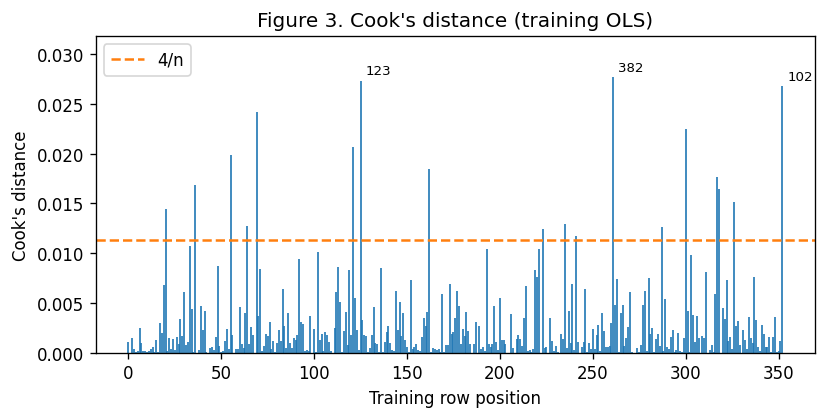

,sample_id,cooks_distance
261,382,0.028
125,123,0.027
352,102,0.027


Rows above 4/n: 18


In [8]:
ols_X = sm.add_constant(StandardScaler().fit_transform(X_train))
ols_fit = sm.OLS(y_train.to_numpy(), ols_X).fit()
cook = ols_fit.get_influence().cooks_distance[0]
threshold = 4 / len(X_train)
influence = pd.DataFrame({'sample_id': X_train.index, 'cooks_distance': cook})
fig, ax = plt.subplots()
ax.vlines(np.arange(len(cook)), 0, cook, linewidth=1)
ax.axhline(threshold, color='tab:orange', linestyle='--', label='4/n')
for pos in np.argsort(cook)[-3:]:
    ax.annotate(str(X_train.index[pos]), (pos, cook[pos]), xytext=(3, 4),
                textcoords='offset points', fontsize=8)
ax.set(title="Figure 3. Cook's distance (training OLS)", xlabel='Training row position',
       ylabel="Cook's distance", ylim=(0, cook.max()*1.15))
ax.legend()
fig.tight_layout()
plt.show()
display(influence.nlargest(3, 'cooks_distance'))
print('Rows above 4/n:', (cook > threshold).sum())

18 rows exceed the threshold; row 382 has the largest distance. Such rows can shift OLS coefficients. Keep them rather than automatically deleting them.

### Figure 4: Learning Curve
Use training data and five-fold CV, keeping the selected alpha fixed.

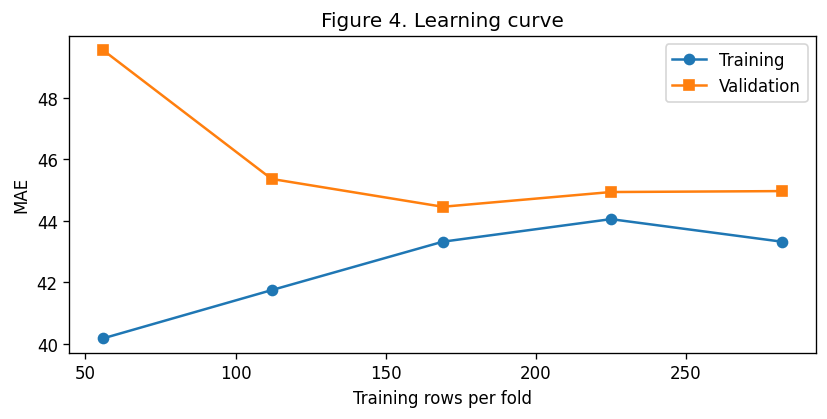

,training_rows,train_MAE,validation_MAE
0,56,40.183,49.532
1,112,41.746,45.358
2,169,43.319,44.453
3,225,44.052,44.932
4,282,43.319,44.963


In [9]:
train_sizes, train_scores, valid_scores = learning_curve(
    final_model, X_train, y_train, cv=cv, scoring='neg_mean_absolute_error',
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], shuffle=True, random_state=SEED)
learning_table = pd.DataFrame({'training_rows': train_sizes,
    'train_MAE': -train_scores.mean(axis=1), 'validation_MAE': -valid_scores.mean(axis=1)})
fig, ax = plt.subplots()
ax.plot(train_sizes, learning_table['train_MAE'], 'o-', label='Training')
ax.plot(train_sizes, learning_table['validation_MAE'], 's-', label='Validation')
ax.set(title='Figure 4. Learning curve', xlabel='Training rows per fold', ylabel='MAE')
ax.legend()
fig.tight_layout()
plt.show()
display(learning_table)

Validation MAE falls from 49.53 to 44.96 and then levels off. The final train-validation gap is small (1.64), so severe overfitting is not evident.

### Critical Slices
Define BMI groups using training tertiles (24.2 and 27.9).

In [10]:
bmi_q1, bmi_q2 = X_train['bmi'].quantile([1/3, 2/3])
results['bmi_slice'] = pd.cut(results['bmi'], [-np.inf, bmi_q1, bmi_q2, np.inf],
                              labels=['Low', 'Middle', 'High'])
slice_table = results.groupby('bmi_slice', observed=False).agg(
    n=('absolute_error', 'size'), MAE=('absolute_error', 'mean'))
display(slice_table)

,n,MAE
bmi_slice,,
Low,38,34.490
Middle,23,47.433
High,28,50.288


The high-BMI group is hardest to predict: MAE 50.29 across 28 test rows.

### Error Cases

In [11]:
error_cases = results.nlargest(3, 'absolute_error')[
    ['sample_id', 'actual', 'predicted', 'absolute_error', 'bmi']]
display(error_cases)
results.to_csv('results.csv', index=False, float_format='%.10f')

,sample_id,actual,predicted,absolute_error,bmi
61,56,52.000,205.195,153.195,30.200
46,77,200.000,74.619,125.381,23.000
1,211,70.000,180.323,110.323,29.800


Rows 56 and 211 are overpredicted despite low actual outcomes; row 77 is underpredicted. The ten inputs do not fully explain individual outcomes.

## 6. Discussion and Limitations
Lasso (alpha 0.1) wins by CV, but Ridge and Lasso barely improve on Linear. Diagnostics show local bias, possible heteroscedasticity, and larger errors in the high-BMI group. More data may help, but the learning curve is flattening.

Coefficients describe associations, not causal effects: correlated features and unmeasured factors can affect them. This small dataset and single split limit generalization, especially for small subgroups. These predictions are not clinical diagnoses.

## 7. Reproducibility
Use Python 3.12 and `requirements.txt`, then restart the kernel and run all cells. The split and CV use seed 42; running the notebook recreates `results.csv`. See README for command-line instructions.